# 14. Adjoints, Normal Operators and the Spectral Theorem
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

In [2]:
rng = np.random.default_rng(0)
Wl = rng.normal(size=(3, 5)); x = rng.normal(size=5); ybar = rng.normal(size=3)
L = lambda x: ybar @ (Wl @ x)                              # a loss that is linear in y
num = np.array([(L(x + 1e-6 * e) - L(x - 1e-6 * e)) / 2e-6 for e in np.eye(5)])
print("finite-difference gradient:", num.round(6)); print("adjoint  W^T ybar        :", (Wl.T @ ybar).round(6))

finite-difference gradient: [ 0.892545  1.771359  2.758433 -0.829573 -0.831527]
adjoint  W^T ybar        : [ 0.892545  1.771359  2.758433 -0.829573 -0.831527]


How a symmetric and a non-symmetric matrix map the unit circle (grey) to an ellipse. Left, a symmetric $A$: the axes of the ellipse lie along the eigenvectors (blue, gold), which are perpendicular, and the eigenvectors are only stretched. Right, a non-symmetric $B$ with the same eigenvalues: its eigenvectors are not perpendicular and do not point along the axes of the ellipse, so the directions of greatest stretching are not eigenvector directions.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


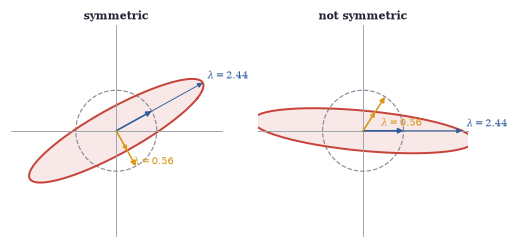

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
for ax, M, title in [(axs[0], np.array([[2.0, 0.8], [0.8, 1.0]]), "symmetric"), (axs[1], None, "not symmetric")]:
    if M is None:
        lam = np.linalg.eigvalsh(axs[0].M); P = np.array([[1, 0.55], [0, 0.85]]); M = P @ np.diag(lam[::-1]) @ np.linalg.inv(P)
    ax.M = M; plane(ax, 2.6, grid=False); unit_circle(ax); circle_image(ax, M, color=RED)
    lam, V = np.linalg.eig(M); idx = np.argsort(-lam.real); lam, V = lam.real[idx], V.real[:, idx]
    for k, col in zip(range(2), [BLUE, GOLD]):
        v = V[:, k] / np.linalg.norm(V[:, k]); v = v if v[0] >= 0 else -v
        arrow(ax, v, color=col, lw=1.0); arrow(ax, lam[k] * v, color=col, lw=0.6)
        ax.text(*(lam[k] * v + (np.array([0.12, 0.1]) if k == 0 else np.array([0.15, -0.35]))), f"$\\lambda={lam[k]:.2f}$", color=col, fontsize=6.5)
    ax.set_title(title, fontsize=7)

In [4]:
rng = np.random.default_rng(4)
S = rng.normal(size=(5, 5)); A = (S + S.T) / 2
lam, Q = np.linalg.eigh(A)
print("Q^T Q = I:", np.allclose(Q.T @ Q, np.eye(5)), "   A = sum lam_k q_k q_k^T:", np.allclose(A, sum(l * np.outer(q, q) for l, q in zip(lam, Q.T))))
N = np.array([[1, -2, 0], [2, 1, 0], [0, 0, 3.]])          # normal, not symmetric
lamN, U = np.linalg.eig(N)
print("N normal:", np.allclose(N @ N.T, N.T @ N), "  eigenvalues:", lamN.round(4), "  unitary eigenvectors:", np.allclose(U.conj().T @ U, np.eye(3)))

Q^T Q = I: True    A = sum lam_k q_k q_k^T: True
N normal: True   eigenvalues: [1.+2.j 1.-2.j 3.+0.j]   unitary eigenvectors: True


The spectral decomposition of a $6\times6$ symmetric matrix $A$ (left) as a sum of rank-one pieces $\lambda_kq_kq_k^{\mathsf T}$, ordered by $\lvert\lambda_k\rvert$. The running sums (bottom row) approach $A$; keeping only the largest few terms already captures its structure, the idea behind low-rank approximation (Chapter 16).

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


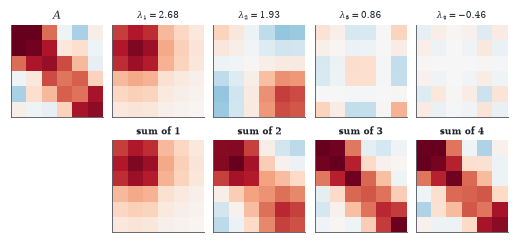

In [5]:
rng = np.random.default_rng(11); x = np.linspace(0, 1, 6)
A6 = np.exp(-8 * (x[:, None] - x[None, :]) ** 2) + 0.15 * (lambda S: S + S.T)(rng.normal(size=(6, 6)))
lam6, Q6 = np.linalg.eigh(A6); order = np.argsort(-np.abs(lam6)); lam6, Q6 = lam6[order], Q6[:, order]
vmax = np.abs(A6).max()
fig, axs = plt.subplots(2, 5, figsize=(W, 2.1))
axs[0, 0].imshow(A6, cmap=CMAP, vmin=-vmax, vmax=vmax); axs[0, 0].set_title("$A$", fontsize=7)
axs[1, 0].axis("off")
run = np.zeros_like(A6)
for k in range(4):
    piece = lam6[k] * np.outer(Q6[:, k], Q6[:, k]); run = run + piece
    axs[0, k + 1].imshow(piece, cmap=CMAP, vmin=-vmax, vmax=vmax); axs[0, k + 1].set_title(f"$\\lambda_{k + 1}={lam6[k]:.2f}$", fontsize=6)
    axs[1, k + 1].imshow(run, cmap=CMAP, vmin=-vmax, vmax=vmax); axs[1, k + 1].set_title(f"sum of {k + 1}", fontsize=6)
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])

Coupled pendulums. Left: the displacements of the two pendulums when only the first is released, showing energy transfer back and forth. Right: the same motion in the eigenbasis of the stiffness matrix: each normal-mode coordinate oscillates independently at its own frequency, and the two frequencies are close, which produces the beats on the left.

Text(0.5, 0, 'time (first 30 units)')

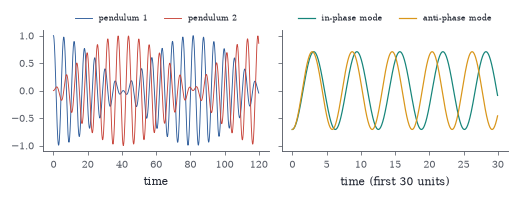

In [6]:
a, s = 1.0, 0.08; K = np.array([[a + s, -s], [-s, a + s]]); lamK, QK = np.linalg.eigh(K)
tt = np.linspace(0, 120, 3000); x0 = np.array([1.0, 0.0]); c0 = QK.T @ x0
modes = c0[:, None] * np.cos(np.sqrt(lamK)[:, None] * tt[None, :]); X = QK @ modes
fig, axs = plt.subplots(1, 2, figsize=(W, 1.7), sharey=True)
axs[0].plot(tt, X[0], color=BLUE, lw=0.6, label="pendulum 1"); axs[0].plot(tt, X[1], color=RED, lw=0.6, label="pendulum 2")
axs[0].legend(fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False); axs[0].set_xlabel("time")
sel = tt <= 30
axs[1].plot(tt[sel], modes[0][sel], color=TEAL, lw=0.8, label="in-phase mode"); axs[1].plot(tt[sel], modes[1][sel], color=GOLD, lw=0.8, label="anti-phase mode")
axs[1].legend(fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False); axs[1].set_xlabel("time (first 30 units)")

The Rayleigh quotient of a symmetric $2\times2$ matrix with eigenvalues $3$ and $1$, as a function of the angle of $v$ (left). Its maximum and minimum occur at the eigenvector directions $\theta_1$ and $\theta_1+90^\circ$; near them the graph is flat, so a direction error of $\varepsilon$ gives an eigenvalue error of order $\varepsilon^2$. Right: the same quadratic form as a landscape $x^{\mathsf T}Ax$, with the unit circle and the eigenvectors along the principal axes of the elliptical level sets.

(np.float64(-1.6), np.float64(1.6), np.float64(-1.6), np.float64(1.6))

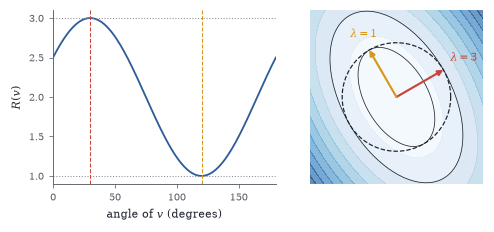

In [7]:
A = np.array([[2.5, 0.866], [0.866, 1.5]]); lam, Q = np.linalg.eigh(A)
th = np.linspace(0, np.pi, 400); V = np.vstack([np.cos(th), np.sin(th)])
R = np.einsum("ik,ij,jk->k", V, A, V)
t1 = np.arctan2(Q[1, 1], Q[0, 1]) % np.pi
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0))
axs[0].plot(np.degrees(th), R, color=BLUE); axs[0].axhline(lam[1], color=GRAY, ls=":", lw=0.7); axs[0].axhline(lam[0], color=GRAY, ls=":", lw=0.7)
axs[0].axvline(np.degrees(t1), color=RED, lw=0.7, ls="--"); axs[0].axvline((np.degrees(t1) + 90) % 180, color=GOLD, lw=0.7, ls="--")
axs[0].set_xlabel(r"angle of $v$ (degrees)"); axs[0].set_ylabel(r"$R(v)$"); axs[0].set_xlim(0, 180)
xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 200), np.linspace(-1.6, 1.6, 200))
qq = A[0, 0] * xx ** 2 + 2 * A[0, 1] * xx * yy + A[1, 1] * yy ** 2
axs[1].contourf(xx, yy, qq, levels=12, cmap="Blues", alpha=0.6); axs[1].contour(xx, yy, qq, levels=[1, 3], colors=[INK], linewidths=0.5)
q1 = Q[:, 1] * np.sign(Q[0, 1]); q2 = Q[:, 0] * np.sign(Q[1, 0])
unit_circle(axs[1], color=INK); arrow(axs[1], q1, color=RED); arrow(axs[1], q2, color=GOLD)
axs[1].text(*(1.15 * q1 + [0.0, 0.08]), r"$\lambda=3$", color=RED, fontsize=7); axs[1].text(*(1.2 * q2 + [-0.25, 0.05]), r"$\lambda=1$", color=GOLD, fontsize=7)
axs[1].set_aspect("equal"); axs[1].axis("off")

Numerical ranges (shaded), traced through their support lines, with eigenvalues marked. Left, a normal matrix: $W(T)$ is exactly the convex hull of the eigenvalues. Right, a non-normal matrix with the same eigenvalues: $W(T)$ is a larger convex set whose boundary bulges far beyond the eigenvalues.

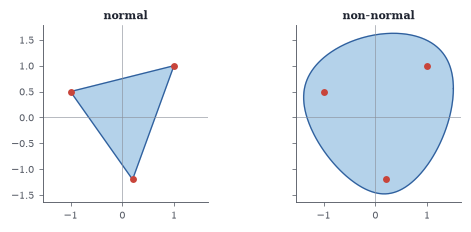

In [8]:
def numrange(M, n=360):
    pts = []
    for t in np.linspace(0, 2 * np.pi, n, endpoint=False):
        H = (np.exp(1j * t) * M + np.exp(-1j * t) * M.conj().T) / 2
        w, V = np.linalg.eigh(H); v = V[:, -1]; pts.append(v.conj() @ M @ v)
    return np.array(pts)
ev = np.array([1 + 1j, -1 + 0.5j, 0.2 - 1.2j])
Un = np.linalg.qr(np.random.default_rng(1).normal(size=(3, 3)) + 1j * np.random.default_rng(2).normal(size=(3, 3)))[0]
Mn = Un @ np.diag(ev) @ Un.conj().T; Mnn = np.diag(ev) + np.array([[0, 1.5, 0.8], [0, 0, 1.2], [0, 0, 0]])
fig, axs = plt.subplots(1, 2, figsize=(W, 2.0), sharex=True, sharey=True)
for ax, M, title in [(axs[0], Mn, "normal"), (axs[1], Mnn, "non-normal")]:
    b = numrange(M); ax.fill(b.real, b.imag, color=SKY, alpha=0.5); ax.plot(np.r_[b.real, b.real[0]], np.r_[b.imag, b.imag[0]], color=BLUE, lw=0.8)
    ax.plot(ev.real, ev.imag, "o", color=RED, ms=3.5); ax.set_aspect("equal"); ax.set_title(title, fontsize=7)
    ax.axhline(0, color=GRAY, lw=0.4); ax.axvline(0, color=GRAY, lw=0.4)

Spectral clustering with the Laplacian. Left: a random graph with two communities (dense inside, sparse between). Middle: the smallest eigenvalues of $L=D-A$, with one zero eigenvalue and a small $\lambda_2$. Right: the Fiedler vector's entries, sorted by vertex; their signs (blue/red) recover the two communities with no knowledge of the true labels.

community recovered: 1.0


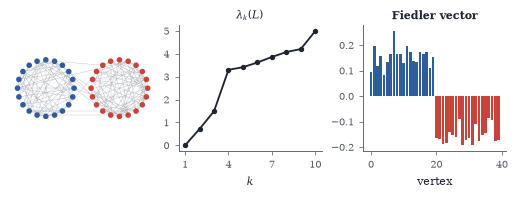

In [9]:
rng = np.random.default_rng(7); n = 40; lab = np.r_[np.zeros(20), np.ones(20)]
P = np.where(lab[:, None] == lab[None, :], 0.35, 0.03); Adj = np.triu(rng.random((n, n)) < P, 1); Adj = (Adj | Adj.T).astype(float)
L = np.diag(Adj.sum(1)) - Adj; lamL, VL = np.linalg.eigh(L); fied = VL[:, 1]
ang = 2 * np.pi * (np.arange(n) % 20) / 20
pos = np.c_[np.cos(ang) + 2.6 * (lab - 0.5), np.sin(ang)]
fig, axs = plt.subplots(1, 3, figsize=(W, 1.7))
for i, j in zip(*np.nonzero(np.triu(Adj))):
    axs[0].plot(*pos[[i, j]].T, color=GRAY, lw=0.25, alpha=0.6)
axs[0].scatter(*pos.T, c=[BLUE if f > 0 else RED for f in fied], s=7, zorder=3); axs[0].set_aspect("equal"); axs[0].axis("off")
axs[1].plot(range(1, 11), lamL[:10], "o-", color=INK, ms=2.5); axs[1].set_xticks([1, 4, 7, 10]); axs[1].set_xlabel("$k$"); axs[1].set_title(r"$\lambda_k(L)$", fontsize=7)
axs[2].bar(range(n), fied, color=[BLUE if f > 0 else RED for f in fied]); axs[2].set_xlabel("vertex"); axs[2].set_title("Fiedler vector", fontsize=7)
print("community recovered:", max(np.mean((fied > 0) == lab), np.mean((fied > 0) != lab)))

In [10]:
rng = np.random.default_rng(5)
S = rng.normal(size=(6, 6)); Asym = S + S.T
J = np.diag(np.ones(5), 1) * 1.0 + np.diag(np.zeros(6))          # nilpotent Jordan block, eigenvalue 0
for name, M in [("symmetric", Asym), ("Jordan block", J)]:
    v = rng.normal(size=6); v /= np.linalg.norm(v); lam = v @ M @ v
    res = np.linalg.norm(M @ v - lam * v); dist = np.min(np.abs(np.linalg.eigvals(M) - lam))
    print(f"{name:13s} residual {res:.3f}   distance to nearest eigenvalue {dist:.3f}")

symmetric     residual 3.566   distance to nearest eigenvalue 0.337
Jordan block  residual 0.746   distance to nearest eigenvalue 0.105


In [11]:
rng = np.random.default_rng(6)
for name, M in [("random", rng.normal(size=(5, 5))), ("normal", (lambda Q: Q @ np.diag(rng.normal(size=5) + 1j * rng.normal(size=5)) @ Q.conj().T)(np.linalg.qr(rng.normal(size=(5, 5)))[0]))]:
    lam = np.linalg.eigvals(M)
    print(f"{name:7s} sum|lambda|^2 = {np.sum(abs(lam) ** 2):8.4f}   ||M||_F^2 = {np.linalg.norm(M) ** 2:8.4f}")

random  sum|lambda|^2 =  12.2152   ||M||_F^2 =  31.6662
normal  sum|lambda|^2 =   7.1510   ||M||_F^2 =   7.1510
